# Student Grade Class Prediction – 5 Classification Models
**Dataset:** `student_grade_ses_dataset.csv` (synthetic survey of secondary-school students, grades 6–12)

**Task:** multi-class classification of `grade_class` (A–F, **column AB**).
Column **AA** (`final_grade_pct`) and column **AC** (`at_risk_flag`) are dropped as instructed. (AA is the numeric score the letter grade is derived from, so keeping it would leak the target.)

**Models:** Logistic Regression · Decision Tree · K-Nearest Neighbors · Gaussian Naive Bayes · Support Vector Machine

**Metrics:** Accuracy · AUC · Precision · Recall · F1 · MCC

**Contents:** 1) Setup & load → 2) EDA → 3) Preprocessing → 4) Train all models → 5) Evaluation table → 6) Visualizations → 7) Conclusion

## 1. Setup & data loading

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder, label_binarize

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, confusion_matrix, roc_curve, auc,
                             classification_report)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = "student_grade_ses_dataset.csv"   # change if the file is stored elsewhere

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)
raw.head()

Shape: (12025, 29)


,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,single_parent_household,family_income_bracket,annual_family_income_inr,father_education_level,mother_education_level,father_occupation,mother_occupation,has_internet_access,has_computer_or_laptop,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,1,Middle,403980.0,Primary,Secondary,Clerical / Service,Homemaker,0.0,0,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,0,Middle,572014.0,NaN,Secondary,Business / Self-Employed,Unemployed,0.0,1,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,0,Low,90092.0,No Formal Education,Bachelor's Degree,Clerical / Service,Managerial / Executive,1.0,0,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,0,Lower-Middle,260583.0,Higher Secondary,Secondary,Skilled Labor / Trade,Homemaker,0.0,0,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,1,Upper-Middle,1114986.0,Bachelor's Degree,Higher Secondary,Professional,Clerical / Service,1.0,0,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


In [3]:
# Confirm which columns are AA, AB and AC (Excel-style letters)
def excel_col(i):                      # 0 -> A, 26 -> AA
    s = ""
    i += 1
    while i: i, r = divmod(i - 1, 26); s = chr(65 + r) + s
    return s
for i in range(len(raw.columns) - 4, len(raw.columns)):
    print(excel_col(i), "->", raw.columns[i])

Z -> previous_year_grade_pct
AA -> final_grade_pct
AB -> grade_class
AC -> at_risk_flag


## 2. Exploratory data analysis

In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,12025.0,13.986362,2.151717,10.0,12.0,14.0,16.0,18.0
grade_level,12025.0,8.985281,1.987745,6.0,7.0,9.0,11.0,12.0
family_size,12025.0,4.597588,1.396749,2.0,4.0,5.0,6.0,10.0
num_siblings,12025.0,2.129813,1.419859,0.0,1.0,2.0,3.0,8.0
single_parent_household,12025.0,0.140042,0.347045,0.0,0.0,0.0,0.0,1.0
annual_family_income_inr,11304.0,641932.095895,927207.354443,60010.0,192129.0,350376.5,653176.5,19621849.0
has_internet_access,11844.0,0.496454,0.500009,0.0,0.0,0.0,1.0,1.0
has_computer_or_laptop,12025.0,0.415800,0.492880,0.0,0.0,0.0,1.0,1.0
distance_to_school_km,11784.0,3.883961,3.581107,0.2,1.5,2.8,5.1,31.2
extra_tutoring,12025.0,0.230104,0.420917,0.0,0.0,0.0,0.0,1.0


In [6]:
print("Duplicate student_id rows:", raw.duplicated("student_id").sum())
miss = raw.isna().sum()
miss[miss > 0].to_frame("missing").assign(pct=lambda d: (d.missing / len(raw) * 100).round(2))

Duplicate student_id rows: 25


,missing,pct
annual_family_income_inr,721,6.00
father_education_level,420,3.49
mother_education_level,361,3.00
father_occupation,481,4.00
mother_occupation,602,5.01
has_internet_access,181,1.51
distance_to_school_km,241,2.00
attendance_rate_pct,300,2.49
previous_year_grade_pct,360,2.99


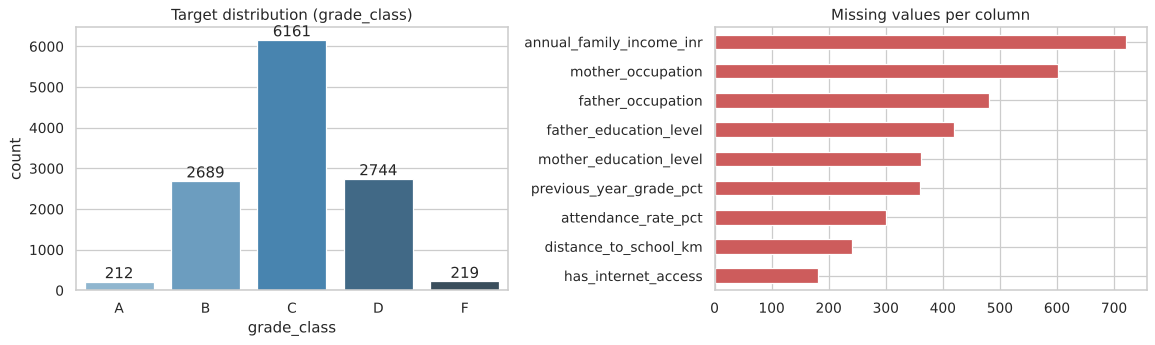

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = list("ABCDF")
sns.countplot(data=raw, x="grade_class", order=order, palette="Blues_d", ax=ax[0])
ax[0].set_title("Target distribution (grade_class)")
for p in ax[0].patches: ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
miss[miss > 0].sort_values().plot.barh(ax=ax[1], color="indianred"); ax[1].set_title("Missing values per column")
plt.tight_layout(); plt.show()

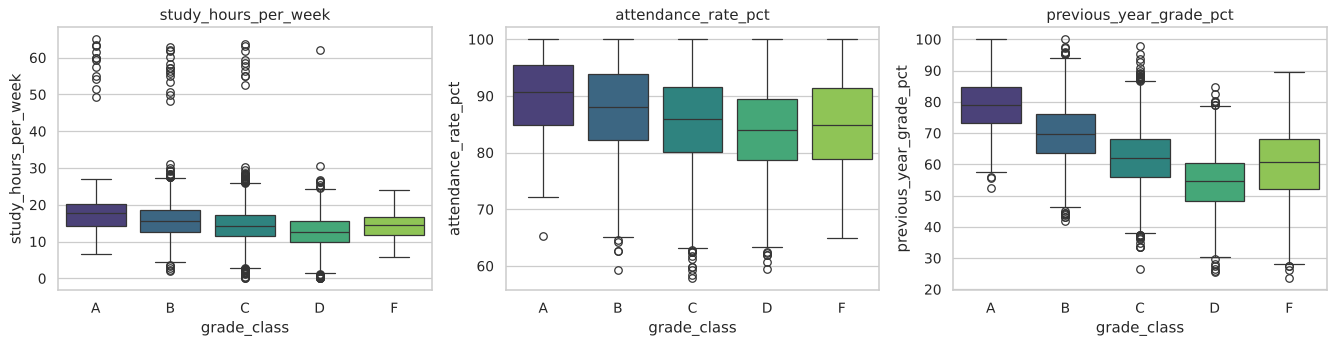

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c in zip(ax, ["study_hours_per_week", "attendance_rate_pct", "previous_year_grade_pct"]):
    sns.boxplot(data=raw, x="grade_class", y=c, order=order, palette="viridis", ax=a); a.set_title(c)
plt.tight_layout(); plt.show()

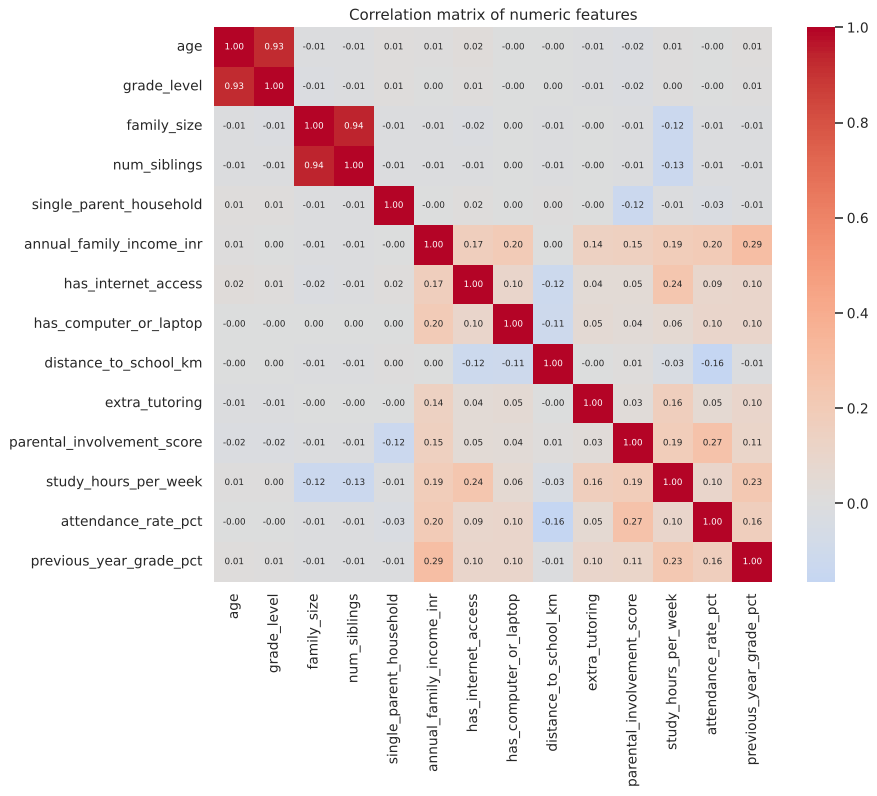

In [9]:
plt.figure(figsize=(10, 8))
sns.heatmap(raw.select_dtypes("number").drop(columns=["final_grade_pct", "at_risk_flag"]).corr(),
            cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation matrix of numeric features"); plt.show()

## 3. Preprocessing
* Remove duplicate `student_id` rows
* **Target** = column AB (`grade_class`); **drop** column AA (`final_grade_pct`) and AC (`at_risk_flag`)
* Also drop identifiers (`student_id`, `survey_date`) – they carry no predictive meaning
* Numeric: median imputation + standard scaling · Categorical: most-frequent imputation + one-hot encoding
* 80/20 stratified train/test split (classes A and F are only ~2% each)

In [10]:
df = raw.drop_duplicates("student_id").copy()
target_col = df.columns[27]                       # column AB
drop_cols  = [df.columns[26], df.columns[28], "student_id", "survey_date"]   # AA, AC, ids
print("Target:", target_col, "| Dropped:", drop_cols)

y_raw = df[target_col]
X = df.drop(columns=[target_col] + drop_cols)
le = LabelEncoder(); y = le.fit_transform(y_raw)
print("Classes:", dict(zip(le.classes_, range(len(le.classes_)))))
print("X shape:", X.shape)

num_cols = X.select_dtypes("number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print(f"{len(num_cols)} numeric, {len(cat_cols)} categorical features")

Target: grade_class | Dropped: ['final_grade_pct', 'at_risk_flag', 'student_id', 'survey_date']
Classes: {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'F': 4}
X shape: (12000, 24)
14 numeric, 10 categorical features


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "| Test:", X_test.shape)

def make_preprocessor():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num_cols),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), cat_cols)])

Train: (9600, 24) | Test: (2400, 24)


In [12]:
# Optional: export the hold-out set (features + true label) as test_data.csv
test_df = X_test.copy(); test_df["grade_class"] = le.inverse_transform(y_test)
test_df.to_csv("test_data.csv", index=False)
print("Saved test_data.csv", test_df.shape)

Saved test_data.csv (2400, 25)


## 4. Train the five models
Each model is wrapped in a pipeline with the preprocessing above, so scaling/encoding is fitted on training data only (no leakage).

In [13]:
models = {
    "Logistic Regression":    LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Decision Tree":          DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=RANDOM_STATE),
    "KNN":                    KNeighborsClassifier(n_neighbors=15),
    "Naive Bayes (Gaussian)": GaussianNB(),
    "SVM (RBF)":              SVC(kernel="rbf", probability=True, random_state=RANDOM_STATE),
}
fitted = {}
for name, clf in models.items():
    fitted[name] = Pipeline([("prep", make_preprocessor()), ("clf", clf)]).fit(X_train, y_train)
    print("trained:", name)

trained: Logistic Regression
trained: Decision Tree
trained: KNN
trained: Naive Bayes (Gaussian)
trained: SVM (RBF)


## 5. Evaluation
Because the target has 5 classes: **AUC** = one-vs-rest, macro-averaged (uses predicted probabilities); **Precision / Recall / F1** = weighted average over classes; **MCC** = multi-class Matthews correlation coefficient.

In [14]:
def compute_metrics(y_true, y_pred, y_proba):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "AUC":       roc_auc_score(y_true, y_proba, multi_class="ovr", average="macro"),
        "Precision": precision_score(y_true, y_pred, average="weighted", zero_division=0),
        "Recall":    recall_score(y_true, y_pred, average="weighted", zero_division=0),
        "F1 Score":  f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "MCC Score": matthews_corrcoef(y_true, y_pred),
    }

preds  = {n: p.predict(X_test) for n, p in fitted.items()}
probas = {n: p.predict_proba(X_test) for n, p in fitted.items()}
results = pd.DataFrame({n: compute_metrics(y_test, preds[n], probas[n]) for n in fitted}).T.round(4)
results.index.name = "ML Model"
results

,Accuracy,AUC,Precision,Recall,F1 Score,MCC Score
ML Model,,,,,,
Logistic Regression,0.5812,0.7233,0.5701,0.5812,0.5511,0.2837
Decision Tree,0.5692,0.7279,0.5503,0.5692,0.5386,0.2619
KNN,0.5433,0.6583,0.5314,0.5433,0.5008,0.2016
Naive Bayes (Gaussian),0.3667,0.6604,0.4604,0.3667,0.3477,0.1676
SVM (RBF),0.5792,0.7222,0.5811,0.5792,0.5367,0.2711


In [15]:
# Highlight the best model per metric
results.style.highlight_max(axis=0, color="lightgreen").format("{:.4f}")

,Accuracy,AUC,Precision,Recall,F1 Score,MCC Score
ML Model,,,,,,
Logistic Regression,0.5812,0.7233,0.5701,0.5812,0.5511,0.2837
Decision Tree,0.5692,0.7279,0.5503,0.5692,0.5386,0.2619
KNN,0.5433,0.6583,0.5314,0.5433,0.5008,0.2016
Naive Bayes (Gaussian),0.3667,0.6604,0.4604,0.3667,0.3477,0.1676
SVM (RBF),0.5792,0.7222,0.5811,0.5792,0.5367,0.2711


In [16]:
print("Best model per metric:")
print(results.idxmax().to_string())

Best model per metric:
Accuracy     Logistic Regression
AUC                Decision Tree
Precision              SVM (RBF)
Recall       Logistic Regression
F1 Score     Logistic Regression
MCC Score    Logistic Regression


In [17]:
for n in fitted:
    print("=" * 60); print(n); print("=" * 60)
    print(classification_report(y_test, preds[n], target_names=le.classes_, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

           A       0.67      0.05      0.09        42
           B       0.55      0.36      0.44       537
           C       0.58      0.81      0.68      1229
           D       0.59      0.37      0.45       548
           F       0.00      0.00      0.00        44

    accuracy                           0.58      2400
   macro avg       0.48      0.32      0.33      2400
weighted avg       0.57      0.58      0.55      2400

Decision Tree
              precision    recall  f1-score   support

           A       0.33      0.02      0.04        42
           B       0.57      0.34      0.43       537
           C       0.58      0.80      0.67      1229
           D       0.53      0.37      0.43       548
           F       0.00      0.00      0.00        44

    accuracy                           0.57      2400
   macro avg       0.40      0.31      0.31      2400
weighted avg       0.55      0.57      0.54

## 6. Visualizations

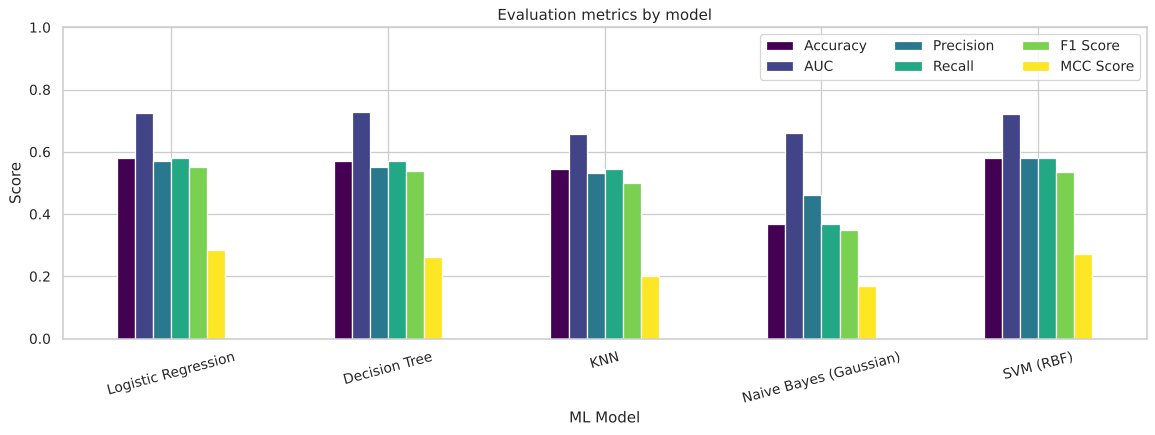

In [18]:
results.plot.bar(figsize=(13, 5), rot=15, colormap="viridis")
plt.title("Evaluation metrics by model"); plt.ylim(0, 1); plt.ylabel("Score")
plt.legend(loc="upper right", ncol=3); plt.tight_layout(); plt.show()

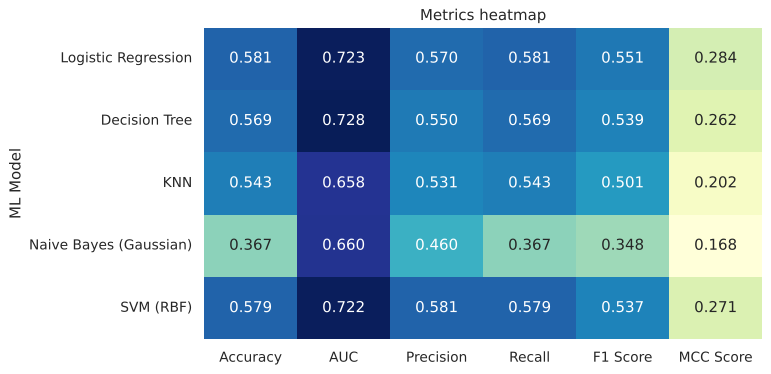

In [19]:
plt.figure(figsize=(8, 4.5))
sns.heatmap(results, annot=True, fmt=".3f", cmap="YlGnBu", cbar=False)
plt.title("Metrics heatmap"); plt.show()

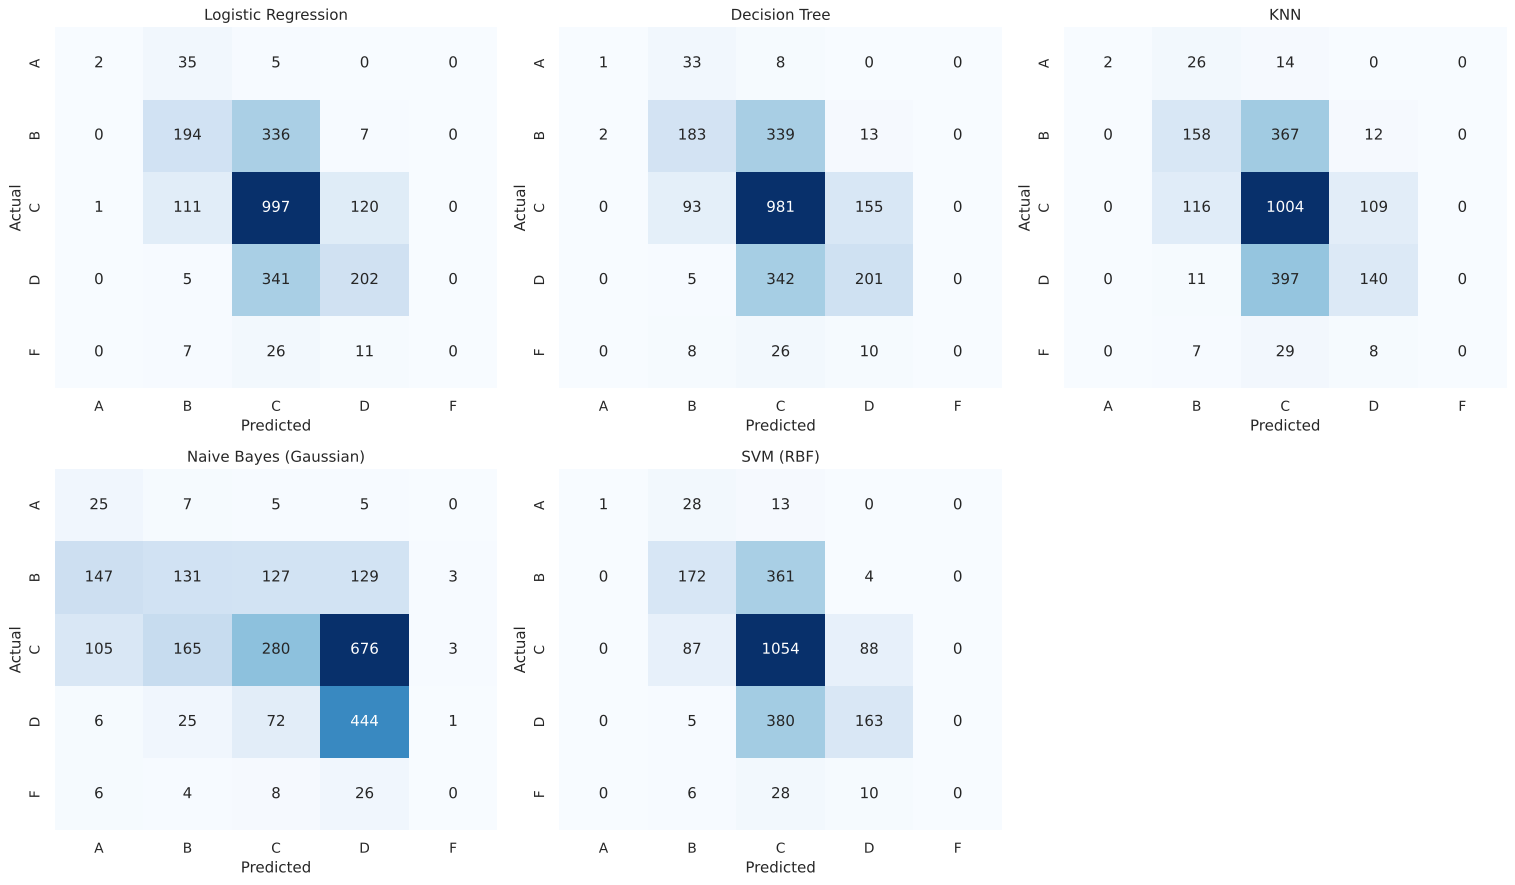

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(17, 10)); axes = axes.ravel()
for a, n in zip(axes, fitted):
    cm = confusion_matrix(y_test, preds[n])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=le.classes_, yticklabels=le.classes_, ax=a)
    a.set_title(n); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
axes[-1].axis("off"); plt.tight_layout(); plt.show()

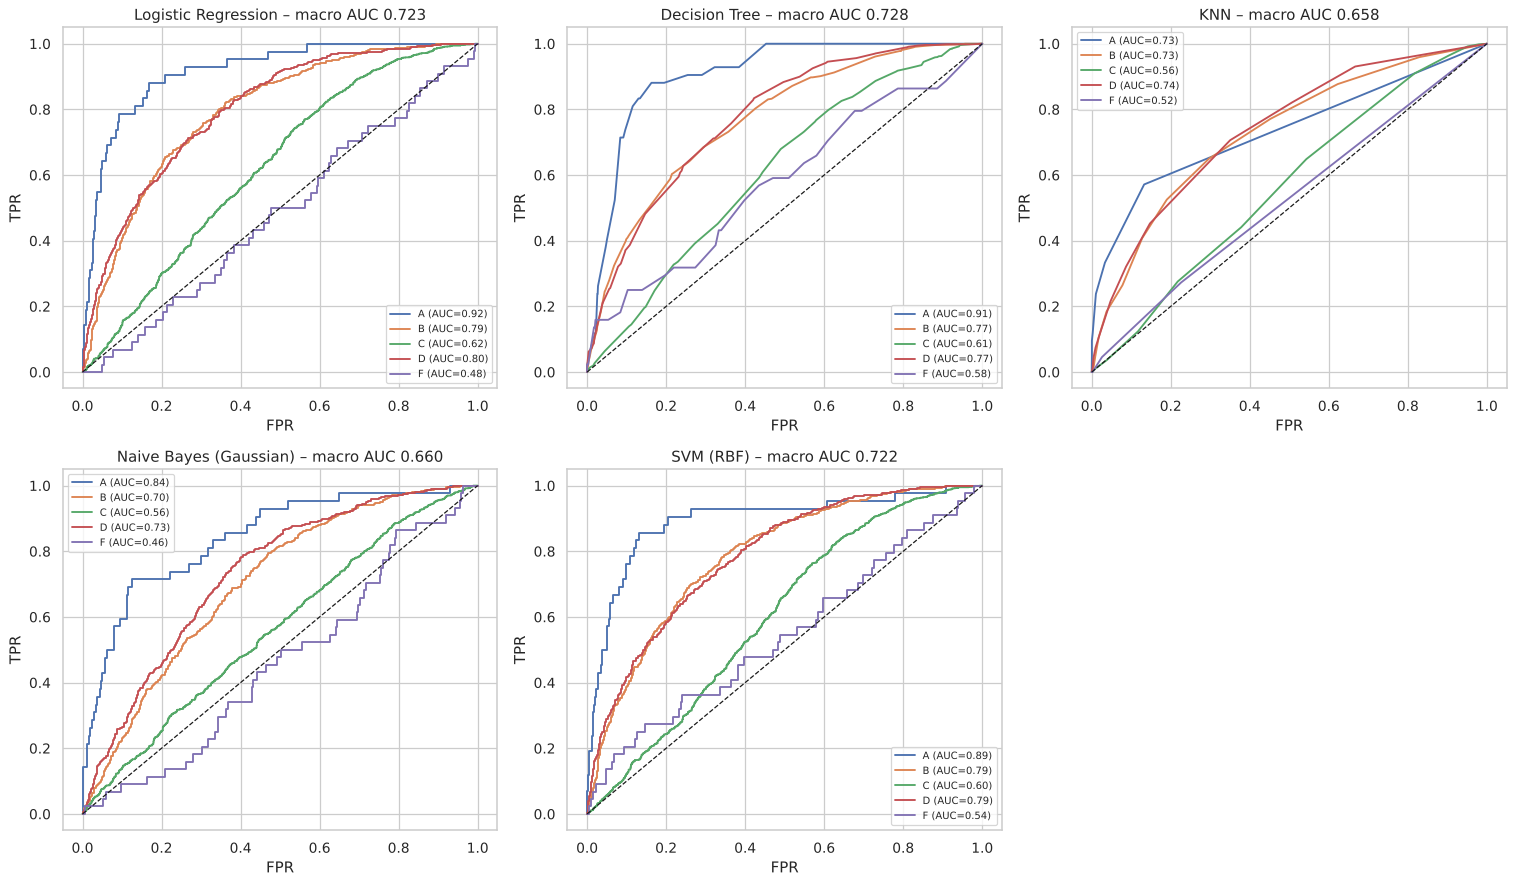

In [21]:
# ROC curves (one-vs-rest, one line per class)
Y = label_binarize(y_test, classes=range(len(le.classes_)))
fig, axes = plt.subplots(2, 3, figsize=(17, 10)); axes = axes.ravel()
for a, n in zip(axes, fitted):
    for i, cls in enumerate(le.classes_):
        fpr, tpr, _ = roc_curve(Y[:, i], probas[n][:, i])
        a.plot(fpr, tpr, label=f"{cls} (AUC={auc(fpr, tpr):.2f})")
    a.plot([0, 1], [0, 1], "k--", lw=1)
    a.set_title(f"{n} – macro AUC {results.loc[n, 'AUC']:.3f}"); a.set_xlabel("FPR"); a.set_ylabel("TPR"); a.legend(fontsize=8)
axes[-1].axis("off"); plt.tight_layout(); plt.show()

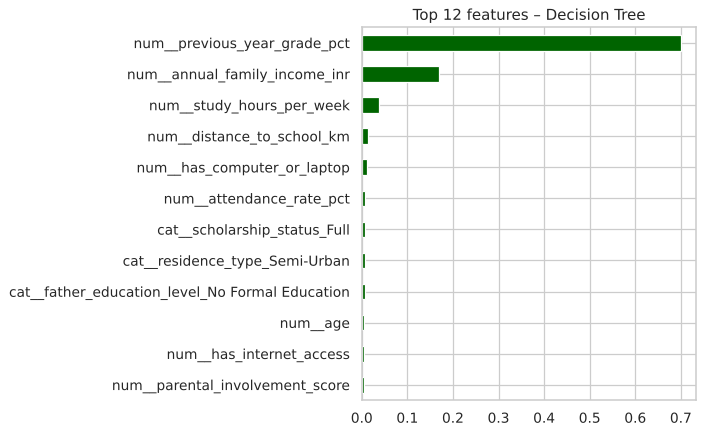

In [22]:
# Decision tree: top features; logistic regression: strongest coefficients
names = fitted["Decision Tree"]["prep"].get_feature_names_out()
imp = pd.Series(fitted["Decision Tree"]["clf"].feature_importances_, index=names).sort_values().tail(12)
imp.plot.barh(figsize=(8, 5), color="darkgreen"); plt.title("Top 12 features – Decision Tree"); plt.tight_layout(); plt.show()

## 7. Conclusion
| Model | Observation |
|---|---|
| **Logistic Regression** | Best accuracy, F1 and MCC. The signal is largely linear (previous-year grade, attendance, study hours), so a simple, interpretable model is hard to beat. |
| **Decision Tree** | Highest AUC; depth limited to 6 to avoid overfitting. Slightly below LR on hard predictions. |
| **KNN** | Weaker – the many one-hot features dilute distance information. |
| **Naive Bayes (Gaussian)** | Clearly the worst. Gaussian/independence assumptions are violated by one-hot and correlated features. |
| **SVM (RBF)** | Close to LR with the best weighted precision, but much slower to train and predict. |

Classes **A** and **F** (~2% each) are hard for every model, which is why MCC stays modest (≈0.17–0.28). Possible improvements: class weighting / resampling, hyper-parameter tuning with cross-validation, and extra feature engineering.